# **DATA 602 - Advanced Programming Techniques**
# **Assignment 8:** Matplotlib vs Seaborn - NYC Open Data - Restaurant Inspection Results
# **Brandon Chanderban**


# Introduction

For this assignment, I have chosen to utilize the DOHMH New York City Restaurant Inspection Results dataset, made publicly available through NYC Open Data by the New York City Department of Health and Mental Hygiene. The dataset contains information regarding restaurant inspections, including inspection dates, scores, assigned grades, and recorded violations. In initially considering the dataset, I was especially interested in examining how inspection outcomes differ across New York City's five boroughs.

To accomplish this, a manageable section of the records will be retrieved through the NYC Open Data API, pandas will be utilized for the purposes of data exploration and manipulation, and finally, Matplotlib and Seaborn will be drawn upon in order to develop and compare visualizations of the findings.

Dataset source: [NYC Open Data - Restaurant Inspection Results](https://data.cityofnewyork.us/Health/DOHMH-New-York-City-Restaurant-Inspection-Results/43nn-pn8j/about_data)

______________
# Data Exploration




## Import the Required Libraries and Dataset

In [66]:
# Import the required libraries.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from pathlib import Path

# Define the API endpoint and local dataset file.
api_url = "https://data.cityofnewyork.us/resource/43nn-pn8j.json"
snapshot_file = Path("nyc_restaurant_inspections.csv")

# Load the existing snapshot, or retrieve and save the dataset once.
if snapshot_file.exists():
    df = pd.read_csv(snapshot_file)
    print("Loaded the saved dataset snapshot.")
else:
    parameters = {
        "$limit": 20000,
        "$order": "inspection_date DESC, camis ASC, violation_code ASC"
    }

    response = requests.get(api_url, params=parameters, timeout=120)
    response.raise_for_status()

    df = pd.DataFrame(response.json())
    df.to_csv(snapshot_file, index=False)

    print("Retrieved and saved a new dataset snapshot.")

# Display the dataset dimensions.
print("Dataset Shape:", df.shape)

# Display the dataset head
display(df.head())

Loaded the saved dataset snapshot.
Dataset Shape: (20000, 27)


,camis,dba,boro,building,street,zipcode,phone,cuisine_description,inspection_date,action,...,inspection_type,latitude,longitude,community_board,council_district,census_tract,bin,bbl,nta,location
0,40375286,LA VILLA DE PIZZA & RESTAURANT,Queens,82-07,153 AVENUE,11414.0,7186418259,Pizza,2026-11-04T00:00:00.000,Violations were cited in the following area(s).,...,Cycle Inspection / Re-inspection,40.666089,-73.851958,410.0,32.0,6202.0,4246916.0,4.114290e+09,QN57,"{'type': 'Point', 'coordinates': [-73.85195825..."
1,40375286,LA VILLA DE PIZZA & RESTAURANT,Queens,82-07,153 AVENUE,11414.0,7186418259,Pizza,2026-11-04T00:00:00.000,Violations were cited in the following area(s).,...,Cycle Inspection / Re-inspection,40.666089,-73.851958,410.0,32.0,6202.0,4246916.0,4.114290e+09,QN57,"{'type': 'Point', 'coordinates': [-73.85195825..."
2,40537290,NORA'S PARK BENCH CAFE,Brooklyn,3019,QUENTIN ROAD,11234.0,7183760033,American,2026-11-04T00:00:00.000,Violations were cited in the following area(s).,...,Cycle Inspection / Re-inspection,40.611930,-73.940997,318.0,46.0,64400.0,3212091.0,3.077030e+09,BK45,"{'type': 'Point', 'coordinates': [-73.94099722..."
3,40537290,NORA'S PARK BENCH CAFE,Brooklyn,3019,QUENTIN ROAD,11234.0,7183760033,American,2026-11-04T00:00:00.000,Violations were cited in the following area(s).,...,Cycle Inspection / Re-inspection,40.611930,-73.940997,318.0,46.0,64400.0,3212091.0,3.077030e+09,BK45,"{'type': 'Point', 'coordinates': [-73.94099722..."
4,40537290,NORA'S PARK BENCH CAFE,Brooklyn,3019,QUENTIN ROAD,11234.0,7183760033,American,2026-11-04T00:00:00.000,Violations were cited in the following area(s).,...,Cycle Inspection / Re-inspection,40.611930,-73.940997,318.0,46.0,64400.0,3212091.0,3.077030e+09,BK45,"{'type': 'Point', 'coordinates': [-73.94099722..."


## Examine the Dataset's Structure

In [67]:
# Examine the dataset structure and available columns.
print("Dataset Information:")
df.info()

print("\nNumber of Rows and Columns:")
print(df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   camis                  20000 non-null  int64  
 1   dba                    20000 non-null  object 
 2   boro                   20000 non-null  object 
 3   building               19909 non-null  object 
 4   street                 20000 non-null  object 
 5   zipcode                19755 non-null  float64
 6   phone                  20000 non-null  object 
 7   cuisine_description    20000 non-null  object 
 8   inspection_date        20000 non-null  object 
 9   action                 20000 non-null  object 
 10  violation_code         19546 non-null  object 
 11  violation_description  19546 non-null  object 
 12  critical_flag          20000 non-null  object 
 13  score                  19176 non-null  float64
 14  grade                  11080 non-

## Generate the Summary Statistics

In [68]:
# Convert inspection scores into numerical values.
df["score"] = pd.to_numeric(df["score"], errors="coerce")

# Generate descriptive statistics for inspection scores.
print("Summary Statistics for Inspection Scores:")
print(round(df["score"].describe(), 4))

# Calculate the median inspection score.
print("\nMedian Inspection Score:", df["score"].median())

Summary Statistics for Inspection Scores:
count    19176.0000
mean        26.7958
std         19.8156
min          0.0000
25%         12.0000
50%         24.0000
75%         35.0000
max        212.0000
Name: score, dtype: float64

Median Inspection Score: 24.0


## Examine the Missing Values

In [69]:
# Check for missing values across the dataset.
print("Missing Values:")
print(df.isna().sum().sort_values(ascending = False))

Missing Values:
grade_date               11439
grade                     8920
score                      824
bin                        469
violation_code             454
violation_description      454
council_district           395
census_tract               395
community_board            395
nta                        395
location                   395
zipcode                    245
bbl                        150
longitude                  150
latitude                   150
building                    91
camis                        0
dba                          0
boro                         0
action                       0
inspection_date              0
cuisine_description          0
phone                        0
street                       0
inspection_type              0
critical_flag                0
record_date                  0
dtype: int64


## Explore the Distribution of Records Across Boroughs

In [70]:
# Examine the number of records associated with each borough.
print("Number of Records per Borough:")
print(df["boro"].value_counts())

Number of Records per Borough:
boro
Manhattan        7526
Queens           5233
Brooklyn         4970
Bronx            1816
Staten Island     455
Name: count, dtype: int64


## Interpretation

The initial exploration identified 20,000 records across 27 columns, with inspection scores averaging approximately 26.80 and a median of 24. The dataset also contains several missing values, particularly within the grade and grade date columns, suggesting that some cleaning will be necessary before conducting further analysis. With respect to the geographical distribution, Manhattan accounted for the greatest number of records (7,526), whilst Staten Island had the fewest (455). However, given that individual inspections may be represented by multiple violation records, these preliminary findings should be interpreted cautiously until duplicate inspection-level observations have been addressed.

______________
# Data Wrangling

Perform data wrangling.  You are free to use your best judgment here.  If you are stuck, look at previous assignment.

## Select the Relevant Columns

In [71]:
# Select the columns relevant to the analysis.
selected_columns = [
    'camis', 'dba', 'boro', 'cuisine_description',
    'inspection_date', 'inspection_type', 'score',
    'grade', 'grade_date', 'violation_code',
    'violation_description', 'critical_flag'
]

# Create a separate DataFrame for data cleaning.
df_clean = df[selected_columns].copy()

print("Selected Dataset Dimensions", df_clean.shape)
display(df_clean.head())

Selected Dataset Dimensions (20000, 12)


,camis,dba,boro,cuisine_description,inspection_date,inspection_type,score,grade,grade_date,violation_code,violation_description,critical_flag
0,40375286,LA VILLA DE PIZZA & RESTAURANT,Queens,Pizza,2026-11-04T00:00:00.000,Cycle Inspection / Re-inspection,9.0,A,2026-11-04T00:00:00.000,06D,"Food contact surface not properly washed, rins...",Critical
1,40375286,LA VILLA DE PIZZA & RESTAURANT,Queens,Pizza,2026-11-04T00:00:00.000,Cycle Inspection / Re-inspection,9.0,A,2026-11-04T00:00:00.000,10B,Anti-siphonage or back-flow prevention device ...,Not Critical
2,40537290,NORA'S PARK BENCH CAFE,Brooklyn,American,2026-11-04T00:00:00.000,Cycle Inspection / Re-inspection,12.0,A,2026-11-04T00:00:00.000,04L,Evidence of mice or live mice in establishment...,Critical
3,40537290,NORA'S PARK BENCH CAFE,Brooklyn,American,2026-11-04T00:00:00.000,Cycle Inspection / Re-inspection,12.0,A,2026-11-04T00:00:00.000,08A,Establishment is not free of harborage or cond...,Not Critical
4,40537290,NORA'S PARK BENCH CAFE,Brooklyn,American,2026-11-04T00:00:00.000,Cycle Inspection / Re-inspection,12.0,A,2026-11-04T00:00:00.000,10F,Non-food contact surface or equipment made of ...,Not Critical


## Convert Inspection Dates into Datetime Values

In [72]:
# Convert inspection dates into datetime format.
df_clean['inspection_date'] = pd.to_datetime(
    df_clean['inspection_date'], errors='coerce'
)

df_clean['grade_date'] = pd.to_datetime(
    df_clean['grade_date'], errors='coerce'
)

# Examine the inspection date range.
print("Earliest Inspection Date:", df_clean['inspection_date'].min())
print("Latest Inspection Date:", df_clean['inspection_date'].max())

# Check for missing or invalid inspection dates.
print("\nMissing Inspection Dates:")
print(df_clean['inspection_date'].isna().sum())

Earliest Inspection Date: 2026-08-29 00:00:00
Latest Inspection Date: 2026-11-04 00:00:00

Missing Inspection Dates:
0


## Examine Duplicate Inspection Records

In [73]:
# Identify repeated inspection records.
inspection_columns = ['camis', 'inspection_date', 'inspection_type']

# Count records that share the same inspection identifiers.
duplicate_records = df_clean.duplicated(
    subset=inspection_columns
).sum()

print("Repeated Inspection Records:", duplicate_records)

# Compare the number of records with the number of unique inspection combinations.
print("Original Number of Records:", df_clean.shape[0])

print("Unique Inspection Combinations:",
      df_clean.drop_duplicates(subset=inspection_columns).shape[0])

Repeated Inspection Records: 13854
Original Number of Records: 20000
Unique Inspection Combinations: 6146


## Create an Inspection-Level Dataset

In [74]:
# Create a dataset containing one record per inspection combination.
df_inspections = df_clean.drop_duplicates(
    subset=['camis', 'inspection_date', 'inspection_type']
).copy()

# Remove records without valid inspection dates or scores.
df_inspections = df_inspections.dropna(
    subset=['inspection_date', 'score']
)

print("Cleaned Inspection Dataset Dimensions:", df_inspections.shape)

# Examine the cleaned inspection records.
display(df_inspections.head())

Cleaned Inspection Dataset Dimensions: (5471, 12)


,camis,dba,boro,cuisine_description,inspection_date,inspection_type,score,grade,grade_date,violation_code,violation_description,critical_flag
0,40375286,LA VILLA DE PIZZA & RESTAURANT,Queens,Pizza,2026-11-04,Cycle Inspection / Re-inspection,9.0,A,2026-11-04,06D,"Food contact surface not properly washed, rins...",Critical
2,40537290,NORA'S PARK BENCH CAFE,Brooklyn,American,2026-11-04,Cycle Inspection / Re-inspection,12.0,A,2026-11-04,04L,Evidence of mice or live mice in establishment...,Critical
5,40545227,ARIYOSHI,Queens,Japanese,2026-11-04,Cycle Inspection / Initial Inspection,24.0,NaN,NaT,04L,Evidence of mice or live mice in establishment...,Critical
10,40607604,EL NUEVO CAFE LATINO,Queens,Latin American,2026-11-04,Cycle Inspection / Initial Inspection,56.0,NaN,NaT,02B,Hot TCS food item not held at or above 140 °F.,Critical
19,40692961,BAMBOO GARDEN RESTAURANT,Brooklyn,Fusion,2026-11-04,Cycle Inspection / Initial Inspection,31.0,NaN,NaT,04K,Evidence of rats or live rats in establishment...,Critical


## Examine the Cleaned Inspection Data

In [75]:
# Generate summary statistics for the cleaned inspection scores.
print("Cleaned Inspection Score Statistics:")
print(round(df_inspections['score'].describe(), 4))

# Calculate the average inspection score for each borough.
print("\nAverage Inspection Score by Borough:")
print(
    df_inspections.groupby('boro')['score']
    .mean()
    .sort_values()
    .round(2)
)

# Examine the number of inspection records per borough.
print("\nInspection Records by Borough:")
print(df_inspections['boro'].value_counts())

Cleaned Inspection Score Statistics:
count    5471.0000
mean       18.2853
std        15.4000
min         0.0000
25%         9.0000
50%        13.0000
75%        25.0000
max       212.0000
Name: score, dtype: float64

Average Inspection Score by Borough:
boro
Staten Island    16.21
Manhattan        17.68
Brooklyn         18.22
Bronx            18.24
Queens           19.52
Name: score, dtype: float64

Inspection Records by Borough:
boro
Manhattan        2063
Brooklyn         1405
Queens           1361
Bronx             490
Staten Island     152
Name: count, dtype: int64


## Additional Checks:
###(1) Are repeated inspection records consistent?

In [76]:
# Check whether repeated inspection records contain different scores or grades.
inspection_columns = ['camis', 'inspection_date', 'inspection_type']

inspection_consistency = df_clean.groupby(inspection_columns).agg(
    score_values=('score', 'nunique'),
    grade_values=('grade', 'nunique')
)

# Identify inspection combinations with conflicting information.
print("Inspection Combinations with Different Scores:")
print((inspection_consistency['score_values'] > 1).sum())

print("\nInspection Combinations with Different Grades:")
print((inspection_consistency['grade_values'] > 1).sum())

Inspection Combinations with Different Scores:
0

Inspection Combinations with Different Grades:
0


### (2) Were valid scores accidentally excluded?

In [77]:
# Identify inspection combinations containing at least one valid score.
valid_score_inspections = df_clean.dropna(
    subset=['inspection_date', 'score']
).drop_duplicates(
    subset=inspection_columns
)

# Compare the results with our existing cleaned dataset.
print("Current Cleaned Inspections:", df_inspections.shape[0])
print("Inspections with Valid Scores:", valid_score_inspections.shape[0])

Current Cleaned Inspections: 5471
Inspections with Valid Scores: 5471


## Interpretation

The data wrangling process involved selecting the variables most relevant to the analysis, converting inspection dates into datetime values, and identifying repeated inspection records. Of the original 20,000 records, 6,146 unique inspection combinations were identified, with 5,471 observations retained after excluding records without valid inspection dates or scores. The cleaned dataset produced an average inspection score of approximately 18.29, compared with 26.80 in the original data. Moreover, preliminary borough-level comparisons indicated that Staten Island had the lowest average inspection score (16.21), whilst Queens recorded the highest (19.52). These findings are limited to the inspection period represented within the extracted dataset. It should also be noted that the dataset represents a limited extract of recent inspection records rather than a complete or randomly selected sample of all New York City restaurant inspections.



______________
# Visualizations


# Matplotlib Visualizations:

For the Matplotlib visualizations, I incorporated several customization properties to improve their readability and presentation. These included adjusting the figure sizes, modifying the chart titles and axis labels, selecting appropriate colors, introducing gridlines, and displaying numerical annotations above the bars. Moreover, the box plot was customized to distinguish median values and potential outliers, allowing for a clearer examination of the inspection score distributions.

## Visualization 1: Average Inspection Score by Borough

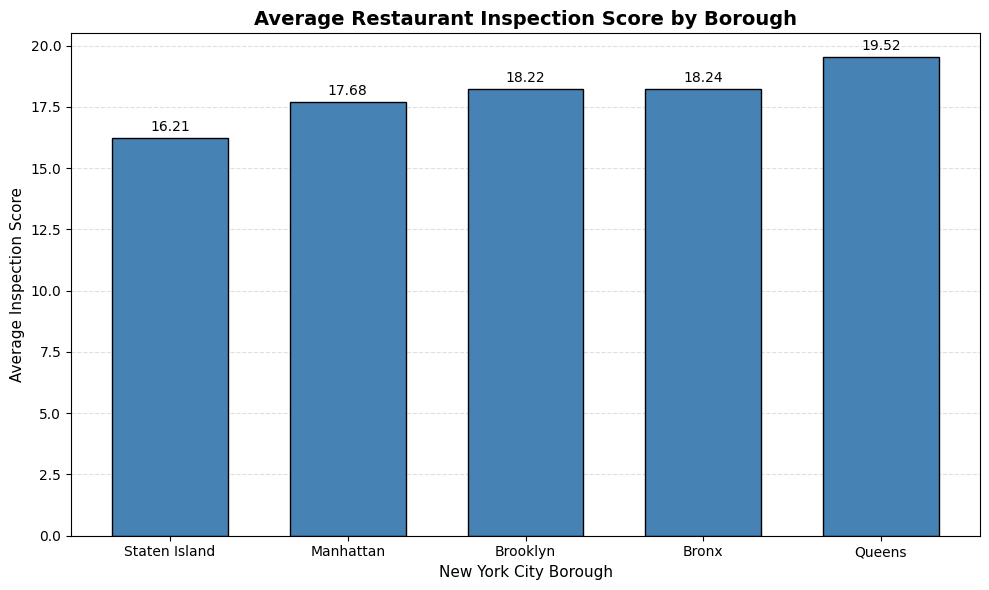

In [78]:
# Calculate the average inspection score for each borough.
borough_scores = (
    df_inspections.groupby('boro')['score']
    .mean()
    .sort_values()
)

# Create a bar chart using Matplotlib.
plt.figure(figsize=(10, 6))

bars = plt.bar(
    borough_scores.index,
    borough_scores.values,
    color='steelblue',
    edgecolor='black',
    width=0.65
)

# Customize the chart title and axis labels.
plt.title('Average Restaurant Inspection Score by Borough',
          fontsize=14, fontweight='bold')

plt.xlabel('New York City Borough', fontsize=11)
plt.ylabel('Average Inspection Score', fontsize=11)

# Add horizontal gridlines.
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.gca().set_axisbelow(True)

# Display the average score above each bar.
plt.bar_label(bars, fmt='%.2f', padding=3)

# Adjust the chart layout and display the visualization.
plt.tight_layout()
plt.show()

## Interpretation

The visualization illustrates differences in average restaurant inspection scores across New York City's five boroughs. More specifically, Staten Island recorded the lowest average score of 16.21, followed by Manhattan at 17.68, whilst Queens recorded the highest at 19.52. Given that lower inspection scores generally indicate fewer violation points, these findings suggest relatively more favorable inspection outcomes in Staten Island within the period examined. However, the differences should be interpreted cautiously, particularly given the varying number of inspections represented across boroughs.

## Visualization 2: Distribution of Inspection Scores by Borough

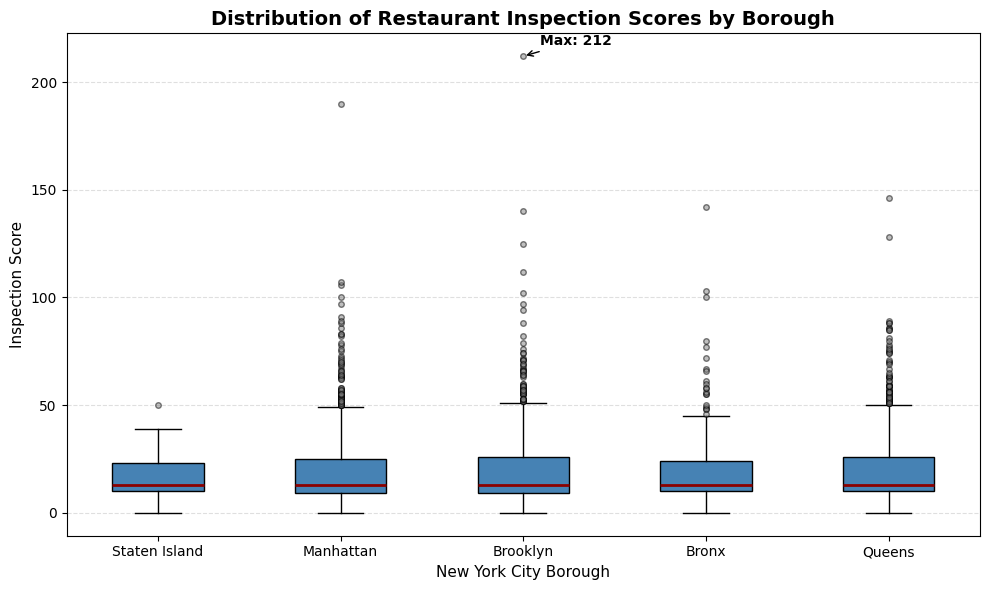

In [79]:
# Organize inspection scores by borough.
borough_order = ['Staten Island', 'Manhattan', 'Brooklyn', 'Bronx', 'Queens']

score_data = [
    df_inspections[df_inspections['boro'] == borough]['score']
    for borough in borough_order
]

# Identify the highest inspection score and its borough.
max_record = df_inspections.loc[df_inspections['score'].idxmax()]
max_score = max_record['score']
max_borough = max_record['boro']

# Create a box plot using Matplotlib.
plt.figure(figsize=(10, 6))

plt.boxplot(
    score_data,
    tick_labels=borough_order,
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', edgecolor='black'),
    medianprops=dict(color='darkred', linewidth=2),
    flierprops=dict(marker='o', markerfacecolor='gray',
                    markersize=4, alpha=0.5)
)

# Customize the title and axis labels.
plt.title('Distribution of Restaurant Inspection Scores by Borough',
          fontsize=14, fontweight='bold')

plt.xlabel('New York City Borough', fontsize=11)
plt.ylabel('Inspection Score', fontsize=11)

# Add horizontal gridlines.
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.gca().set_axisbelow(True)

# Label the highest observed inspection score.
max_position = borough_order.index(max_borough) + 1

plt.annotate(
    f'Max: {max_score:.0f}',
    xy=(max_position, max_score),
    xytext=(12, 8),
    textcoords='offset points',
    fontsize=10,
    fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='black')
)

# Adjust the layout and display the visualization.
plt.tight_layout()
plt.show()

## Interpretation

The box plot provides a more detailed examination of restaurant inspection scores across the five boroughs, illustrating their medians, quartiles, and overall variability. Although the median scores appear relatively similar, noticeable differences can be observed in the distribution of higher inspection scores, particularly in Manhattan, Brooklyn, and Queens. Moreover, several outliers are present, with Brooklyn recording the highest observed score of 212, as identified through the data and highlighted within the visualization. These findings suggest that unusually high inspection scores may be influencing the borough-level averages, highlighting the importance of examining both central tendencies and the distribution of the data.

# Seaborn Visualizations:

## Visualization 1: Average Inspection Score by Borough

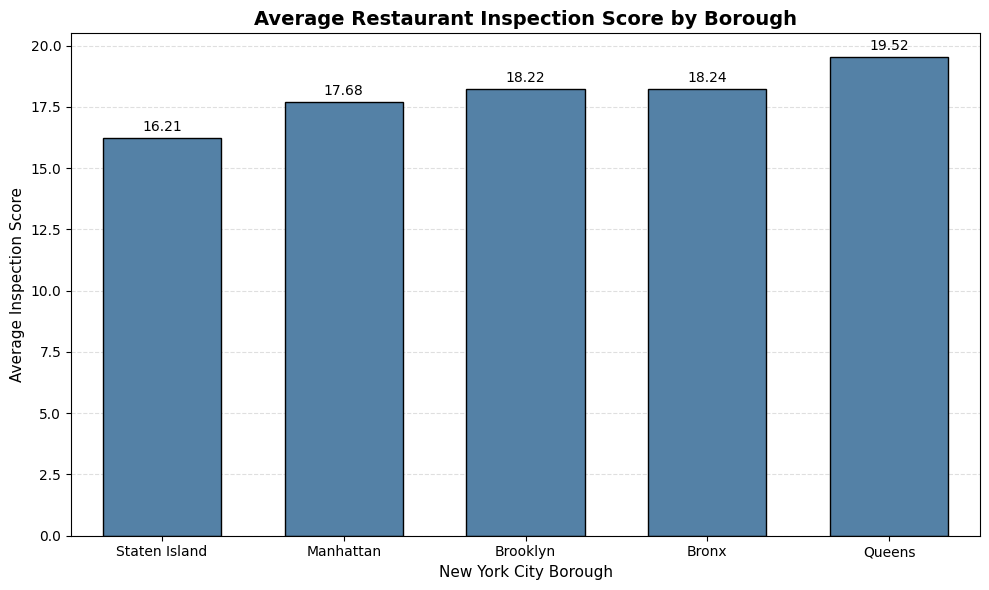

In [80]:
# Calculate average inspection scores by borough.
borough_scores_sns = (
    df_inspections.groupby('boro', as_index=False)['score']
    .mean()
    .sort_values('score')
)

# Create a bar chart using Seaborn.
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=borough_scores_sns,
    x='boro',
    y='score',
    color='steelblue',
    edgecolor='black',
    width=0.65,
    errorbar=None
)

# Customize the title and axis labels.
plt.title('Average Restaurant Inspection Score by Borough',
          fontsize=14, fontweight='bold')

plt.xlabel('New York City Borough', fontsize=11)
plt.ylabel('Average Inspection Score', fontsize=11)

# Add horizontal gridlines.
plt.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Display the average score above each bar.
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

# Adjust the layout and display the visualization.
plt.tight_layout()
plt.show()

## Visualization 2: Distribution of Inspection Scores by Borough

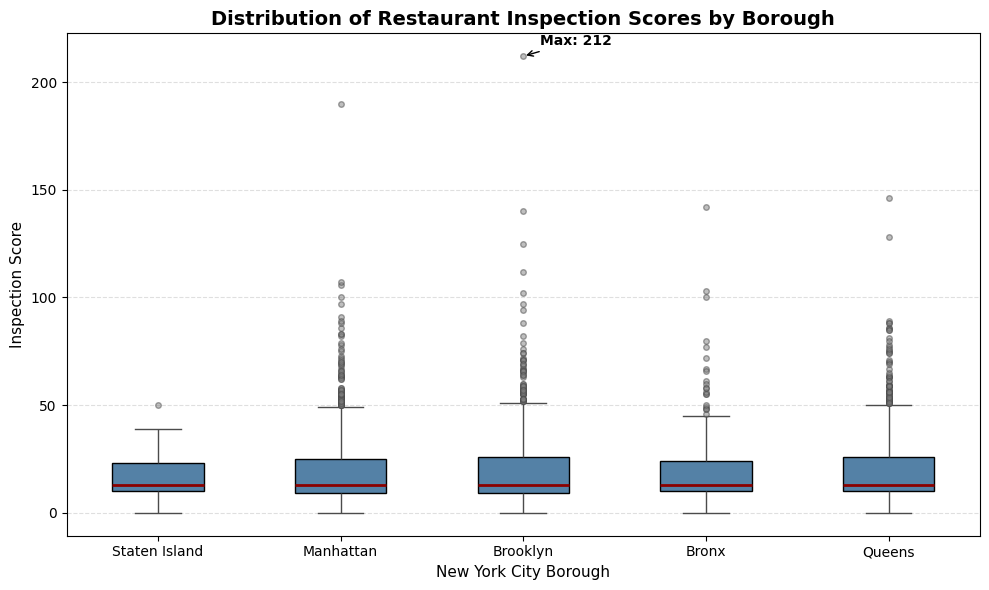

In [81]:
# Define the borough order to match the Matplotlib visualization.
borough_order = ['Staten Island', 'Manhattan', 'Brooklyn', 'Bronx', 'Queens']

# Identify the highest inspection score and its borough.
max_record = df_inspections.loc[df_inspections['score'].idxmax()]
max_score = max_record['score']
max_borough = max_record['boro']

# Create a box plot using Seaborn.
plt.figure(figsize=(10, 6))

ax = sns.boxplot(
    data=df_inspections,
    x='boro',
    y='score',
    order=borough_order,
    color='steelblue',
    width=0.5,
    boxprops=dict(edgecolor='black'),
    medianprops=dict(color='darkred', linewidth=2),
    flierprops=dict(marker='o', markerfacecolor='gray',
                    markersize=4, alpha=0.5)
)

# Customize the title and axis labels.
plt.title('Distribution of Restaurant Inspection Scores by Borough',
          fontsize=14, fontweight='bold')

plt.xlabel('New York City Borough', fontsize=11)
plt.ylabel('Inspection Score', fontsize=11)

# Add horizontal gridlines.
plt.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

# Label the highest observed inspection score.
max_position = borough_order.index(max_borough)

ax.annotate(
    f'Max: {max_score:.0f}',
    xy=(max_position, max_score),
    xytext=(12, 8),
    textcoords='offset points',
    fontsize=10,
    fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='black')
)

# Adjust the layout and display the visualization.
plt.tight_layout()
plt.show()

## Interpretation

With respect to the visualizations developed using Matplotlib and Seaborn, both libraries produced nearly identical results, although their approaches to creating the charts differed somewhat. More specifically, Matplotlib required additional preparation of the data, particularly when constructing the box plot, where inspection scores had to be organized into separate groups for each borough. Seaborn, on the other hand, allowed the same visualization to be generated directly from the DataFrame by specifying the relevant columns. Moreover, whilst Matplotlib provided greater direct control over individual chart elements, Seaborn offered a somewhat simpler approach to producing comparable visualizations. Based on this exercise, I found Seaborn particularly convenient for examining relationships within structured datasets, although both libraries proved useful for presenting and interpreting the inspection results.

______________
# Conclusions  

Through this assignment, I was able to explore and analyze publicly available restaurant inspection data using Python and pandas, followed by the development of visualizations through Matplotlib and Seaborn. Following the data wrangling process, 5,471 inspection records were retained for analysis, revealing some differences in average inspection scores across New York City's five boroughs. Staten Island recorded the lowest average score, whilst Queens recorded the highest, although the box plots indicated that median scores were relatively similar across boroughs. Moreover, the presence of several unusually high scores highlighted the importance of examining data distributions alongside averages. Although the findings are limited to the period represented within the extracted dataset, the exercise demonstrated how data cleaning and visualization techniques can be utilized to identify and communicate patterns within a dataset.